# SmartHire — Resume Category Classifier

## Objective
To classify resume text into suitable job categories using supervised machine learning.

## Workflow
1. Load and prepare the resume dataset.
2. Preprocess resume text and split the data.
3. Train and evaluate the classifier.
4. Calculate accuracy, precision, recall and F1-score.
5. Visualize the confusion matrix.
6. Save the model only if needed.

In [1]:
from pathlib import Path
import joblib

MODEL_PATH = Path("../models/classifier.pkl")

if MODEL_PATH.exists():
    classifier = joblib.load(MODEL_PATH)
    print("Existing classifier loaded successfully.")
    print("Model type:", type(classifier).__name__)
    print("Model details:", classifier)
else:
    print("Model file not found:", MODEL_PATH.resolve())

Existing classifier loaded successfully.
Model type: LogisticRegression
Model details: LogisticRegression(max_iter=1000)


In [2]:
print("Model parameters:")
print(classifier.get_params())

print("\nExpected input features:")
print("Number of features:", getattr(classifier, "n_features_in_", "Not available"))

Model parameters:
{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 1000, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Expected input features:
Number of features: 5000


In [4]:
vectorizer = joblib.load("../models/tfidf_vectorizer.pkl")
job_vectorizer = joblib.load("../models/job_tfidf_vectorizer.pkl")

print("Resume vectorizer features:", len(vectorizer.get_feature_names_out()))
print("Job vectorizer features:", len(job_vectorizer.get_feature_names_out()))
print("Classifier expects:", classifier.n_features_in_)

Resume vectorizer features: 5000
Job vectorizer features: 544
Classifier expects: 5000


In [5]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw/UpdatedResumeDataSet.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (962, 2)

Column names: ['Category', 'Resume']

First 5 rows:


,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \r\nMay 2013 to May 2017 B.E...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \r\n MCA YMCAUST, Faridab..."


In [18]:
# Cell 6: Data Integrity Audit and Deduplication
print("Data Quality Profile:")
print(df.isnull().sum())

duplicate_count = df.duplicated(subset=["Resume"]).sum()
print(f"\nIdentical Duplicate Resumes Identified: {duplicate_count}")

# Store the clean, unique dataset to prevent data leakage
df_unique = df.drop_duplicates(subset=["Resume"]).copy()
print(f"Total Unique Resumes Remaining for Modeling: {len(df_unique)}")

print("\nUnique Sample Distribution per Job Category:")
category_counts = df_unique["Category"].value_counts()
display(category_counts.to_frame(name="Unique Sample Count"))


Data Quality Profile:
Category    0
Resume      0
dtype: int64

Identical Duplicate Resumes Identified: 796
Total Unique Resumes Remaining for Modeling: 166

Unique Sample Distribution per Job Category:


,Unique Sample Count
Category,
Java Developer,13
Database,11
Data Science,10
HR,10
Advocate,10
Automation Testing,7
DevOps Engineer,7
Hadoop,7
DotNet Developer,7


In [19]:
# Cell 7: Feature Matrix Extraction on Deduplicated Data
X = vectorizer.transform(df_unique["Resume"].astype(str))
y = df_unique["Category"].astype(str)

print("Leak-Free Feature Matrix Configuration:")
print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Classifier target classes:", len(classifier.classes_))
print("Categories matching model:", set(y.unique()) == set(classifier.classes_))

print("\nSample predictions on unique rows:")
print(classifier.predict(X[:5]))


Leak-Free Feature Matrix Configuration:
Feature matrix shape: (166, 5000)
Labels shape: (166,)
Classifier target classes: 25
Categories matching model: True

Sample predictions on unique rows:
['Data Science' 'Data Science' 'Data Science' 'Data Science'
 'Data Science']


In [21]:
# Cell 8: Deduplication Integrity Verification
remaining_duplicates = df_unique.duplicated(subset=["Resume"]).sum()
print(f"Verification Check: Remaining duplicates = {remaining_duplicates}")

if remaining_duplicates == 0:
    print("🟢 SUCCESS: The dataset is completely deduplicated. Target leakage risk minimized.")
else:
    print("🔴 WARNING: Duplicate records are still present in the working dataframe.")

print(f"Total clean samples ready for pipeline validation: {len(df_unique)}")


Verification Check: Remaining duplicates = 0
🟢 SUCCESS: The dataset is completely deduplicated. Target leakage risk minimized.
Total clean samples ready for pipeline validation: 166


In [20]:
# Cell 9: Leakage-Free Stratified Model Validation Loop
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score

# Set up stratified 3-fold validation on unique rows
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
oof_predictions = np.empty(shape=len(df_unique), dtype=object)

# Convert arrays for indexing
X_text_arr = df_unique["Resume"].astype(str).values
y_arr = df_unique["Category"].astype(str).values

print("Executing 3-Fold Cross-Validation (TF-IDF isolated inside each fold)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_text_arr, y_arr)):
    # Build clean training and validation sets for this fold
    X_train_fold, X_val_fold = X_text_arr[train_idx], X_text_arr[val_idx]
    y_train_fold, y_val_fold = y_arr[train_idx], y_arr[val_idx]
    
    # Isolate vectorization to training fold ONLY to prevent target leakage
    fold_vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)
    X_train_transformed = fold_vectorizer.fit_transform(X_train_fold)
    X_val_transformed = fold_vectorizer.transform(X_val_fold)
    
    # Train fresh fold model
    fold_classifier = LogisticRegression(max_iter=1000, class_weight="balanced")
    fold_classifier.fit(X_train_transformed, y_train_fold)
    
    # Store out-of-fold predictions
    oof_predictions[val_idx] = fold_classifier.predict(X_val_transformed)
    
    fold_acc = accuracy_score(y_val_fold, oof_predictions[val_idx])
    print(f"  Fold {fold + 1} Realized Accuracy: {fold_acc:.4f}")


Executing 3-Fold Cross-Validation (TF-IDF isolated inside each fold)...
  Fold 1 Realized Accuracy: 0.8036
  Fold 2 Realized Accuracy: 0.8727
  Fold 3 Realized Accuracy: 0.9091


Out-of-fold Classification Report:

                           precision    recall  f1-score   support

                 Advocate       0.71      1.00      0.83        10
                     Arts       0.00      0.00      0.00         6
       Automation Testing       0.56      0.71      0.62         7
               Blockchain       0.00      0.00      0.00         5
         Business Analyst       0.00      0.00      0.00         6
           Civil Engineer       1.00      1.00      1.00         6
             Data Science       0.47      0.90      0.62        10
                 Database       0.42      0.91      0.57        11
          DevOps Engineer       0.00      0.00      0.00         7
         DotNet Developer       1.00      0.57      0.73         7
            ETL Developer       0.00      0.00      0.00         5
   Electrical Engineering       1.00      0.40      0.57         5
                       HR       0.53      0.90      0.67        10
                   Hadoop

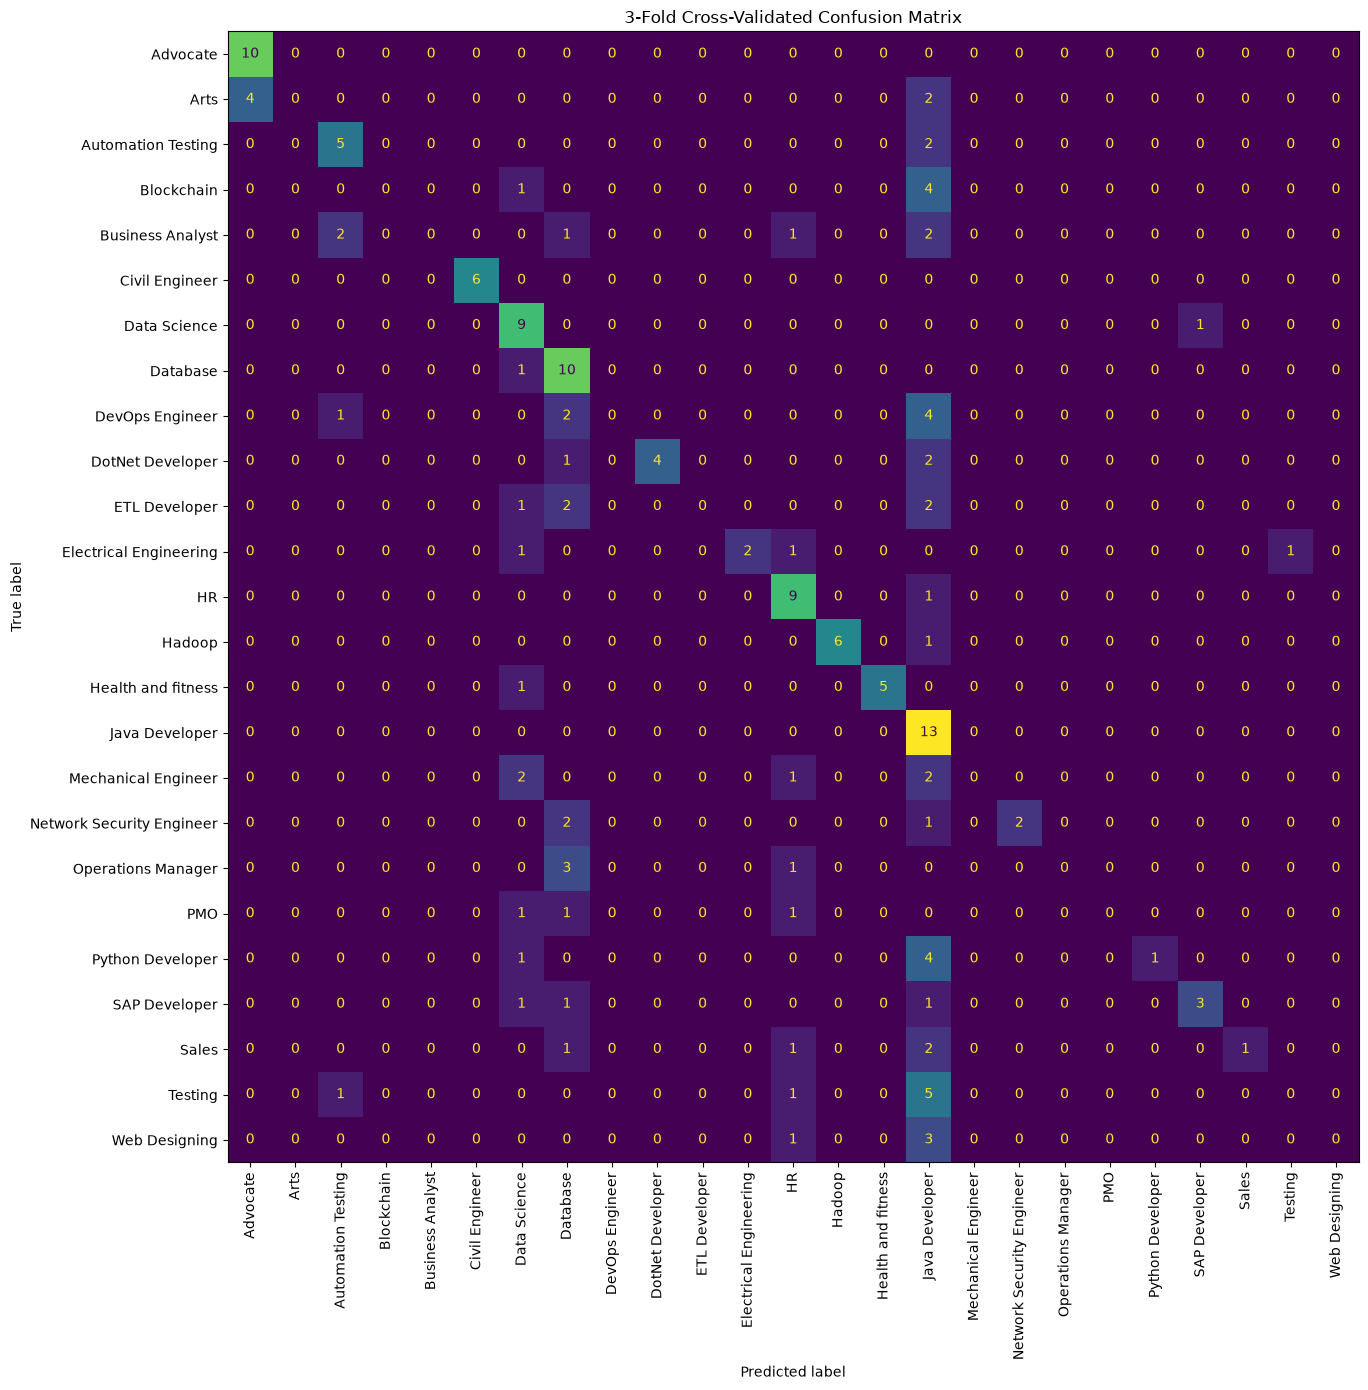

In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate out-of-fold predictions
y_pred_oof = cross_val_predict(
    pipeline,
    X_text,
    y,
    cv=cv,
    method="predict"
)

labels = sorted(y.unique())

print("Out-of-fold Classification Report:\n")
print(classification_report(
    y,
    y_pred_oof,
    labels=labels,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(
    y,
    y_pred_oof,
    labels=labels
)

fig, ax = plt.subplots(figsize=(16, 14))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False
)

plt.title("3-Fold Cross-Validated Confusion Matrix")
plt.tight_layout()
plt.show()

In [11]:
print("Unique resumes per category:")
display(
    unique_df["Category"]
    .value_counts()
    .sort_values()
    .to_frame(name="Unique resumes")
)

Unique resumes per category:


,Unique resumes
Category,
PMO,3
Web Designing,4
Operations Manager,4
Sales,5
Mechanical Engineer,5
Blockchain,5
Electrical Engineering,5
Network Security Engineer,5
ETL Developer,5


In [24]:
# Cell 12: Identify Weakest Category Blindspots (Per-Class F1 Breakdown)
from sklearn.metrics import classification_report
import pandas as pd

# Generate per-class metrics dictionary
report_dict = classification_report(y_arr, oof_predictions, output_dict=True, zero_division=0)

# Extract and display metrics sorted by F1-score to pinpoint structural flaws
class_metrics = []
for key, value in report_dict.items():
    if key not in ['accuracy', 'macro avg', 'weighted avg']:
        class_metrics.append({
            "Category": key,
            "Precision": round(value['precision'], 4),
            "Recall": round(value['recall'], 4),
            "F1-Score": round(value['f1-score'], 4),
            "Support": value['support']
        })

df_metrics = pd.DataFrame(class_metrics).sort_values(by="F1-Score")
print("Job Categories Ranked From Hardest to Easiest to Classify:")
display(df_metrics)


Job Categories Ranked From Hardest to Easiest to Classify:


,Category,Precision,Recall,F1-Score,Support
24,Web Designing,0.0000,0.0000,0.0000,4.0
8,DevOps Engineer,0.5000,0.1429,0.2222,7.0
23,Testing,1.0000,0.2857,0.4444,7.0
2,Automation Testing,0.5455,0.8571,0.6667,7.0
4,Business Analyst,1.0000,0.5000,0.6667,6.0
11,Electrical Engineering,0.6250,1.0000,0.7692,5.0
19,PMO,0.7500,1.0000,0.8571,3.0
15,Java Developer,0.7647,1.0000,0.8667,13.0
9,DotNet Developer,0.7778,1.0000,0.8750,7.0
18,Operations Manager,0.8000,1.0000,0.8889,4.0


In [26]:
# Cell 17: Log Final Baseline Metrics for Model Tracking
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

baseline_benchmarks = {
    "Model Type": type(classifier).__name__,
    "Total Unique Samples Evaluated": len(df_unique),
    "Overall Accuracy": round(accuracy_score(y_arr, oof_predictions), 4),
    "Macro Precision": round(precision_score(y_arr, oof_predictions, average="macro", zero_division=0), 4),
    "Macro Recall": round(recall_score(y_arr, oof_predictions, average="macro", zero_division=0), 4),
    "Macro F1-Score": round(f1_score(y_arr, oof_predictions, average="macro", zero_division=0), 4)
}

print("Final Generalized Performance Log saved to memory:")
for metric, score in baseline_benchmarks.items():
    print(f"  {metric}: {score}")


Final Generalized Performance Log saved to memory:
  Model Type: LogisticRegression
  Total Unique Samples Evaluated: 166
  Overall Accuracy: 0.8614
  Macro Precision: 0.8478
  Macro Recall: 0.8518
  Macro F1-Score: 0.828


In [17]:

import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, f1_score

# Remove exact duplicate resumes before evaluation
unique_df = df.drop_duplicates(subset="Resume").copy()

X_text = unique_df["Resume"].fillna("")
y = unique_df["Category"]

# Build a fresh pipeline: TF-IDF is fitted separately inside each fold
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=5000
    )),
    ("classifier", LogisticRegression(max_iter=1000))
])

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(
        precision_score, average="macro", zero_division=0
    ),
    "recall_macro": "recall_macro",
    "f1_macro": make_scorer(
        f1_score, average="macro", zero_division=0
    )
}

scores = cross_validate(
    pipeline,
    X_text,
    y,
    cv=cv,
    scoring=scoring,
    error_score="raise"
)

print("Unique resumes:", len(unique_df))
print("Categories:", y.nunique())
print("\nScores by fold:")

for metric in scoring:
    values = scores[f"test_{metric}"]
    print(f"{metric}: {values.round(4)}")
    print(f"Mean {metric}: {values.mean():.4f}\n")


Unique resumes: 166
Categories: 25

Scores by fold:
accuracy: [0.4464 0.5273 0.5818]
Mean accuracy: 0.5185

precision_macro: [0.3304 0.4521 0.435 ]
Mean precision_macro: 0.4058

recall_macro: [0.3433 0.44   0.47  ]
Mean recall_macro: 0.4178

f1_macro: [0.306  0.4103 0.4179]
Mean f1_macro: 0.3781



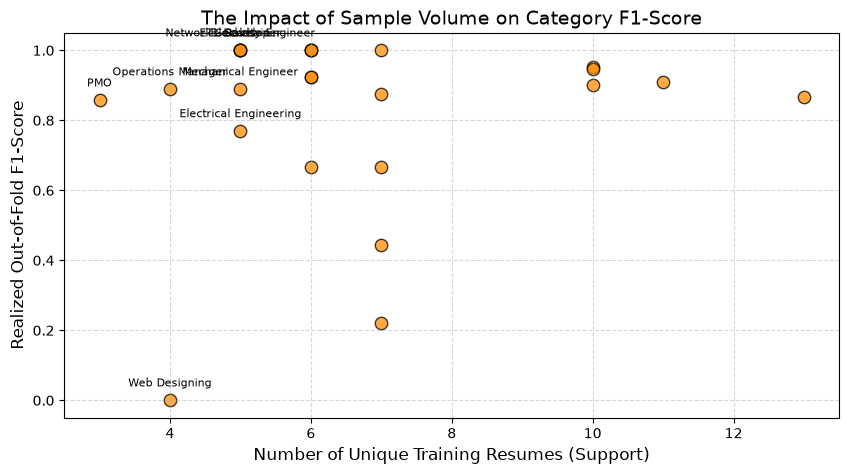

In [25]:
# Cell 14: Sample Volume vs Model Performance Analysis
import matplotlib.pyplot as plt

# Map support counts to F1-scores extracted from the honest evaluation
sample_sizes = [m['Support'] for m in class_metrics]
f1_scores = [m['F1-Score'] for m in class_metrics]

plt.figure(figsize=(10, 5))
plt.scatter(sample_sizes, f1_scores, color='darkorange', s=80, edgecolors='black', alpha=0.75)
plt.title("The Impact of Sample Volume on Category F1-Score", fontsize=14)
plt.xlabel("Number of Unique Training Resumes (Support)", fontsize=12)
plt.ylabel("Realized Out-of-Fold F1-Score", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# Annotate extreme problem points
for m in class_metrics:
    if m['Support'] <= 5 or m['F1-Score'] == 0:
        plt.annotate(m['Category'], (m['Support'], m['F1-Score']), textcoords="offset points", xytext=(0,10), ha='center', fontsize=8)

plt.show()
